In [1]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]), nrows=5)

print("Dataset uploaded successfully!")
print("File:", filename)
display(df)

Saving train_genetic_disorders.csv to train_genetic_disorders.csv
Dataset uploaded successfully!
File: train_genetic_disorders.csv


,Patient Id,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Patient First Name,Family Name,Father's name,...,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Genetic Disorder,Disorder Subclass
0,PID0x6418,2,Yes,No,Yes,No,4.760603,Richard,NaN,Larre,...,NaN,9.857562,NaN,1,1.0,1,1,1.0,Mitochondrial genetic inheritance disorders,Leber's hereditary optic neuropathy
1,PID0x25d5,4,Yes,Yes,No,No,4.910669,Mike,NaN,Brycen,...,Multiple,5.522560,normal,1,NaN,1,1,0.0,NaN,Cystic fibrosis
2,PID0x4a82,6,Yes,No,No,No,4.893297,Kimberly,NaN,Nashon,...,Singular,NaN,normal,0,1.0,1,1,1.0,Multifactorial genetic inheritance disorders,Diabetes
3,PID0x4ac8,12,Yes,No,Yes,No,4.705280,Jeffery,Hoelscher,Aayaan,...,Singular,7.919321,inconclusive,0,0.0,1,0,0.0,Mitochondrial genetic inheritance disorders,Leigh syndrome
4,PID0x1bf7,11,Yes,No,NaN,Yes,4.720703,Johanna,Stutzman,Suave,...,Multiple,4.098210,NaN,0,0.0,0,0,NaN,Multifactorial genetic inheritance disorders,Cancer


In [2]:
import pandas as pd

df = pd.read_csv(filename)

print("Full dataset size:", df.shape)
display(df.head())

Full dataset size: (22083, 45)


,Patient Id,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Patient First Name,Family Name,Father's name,...,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Genetic Disorder,Disorder Subclass
0,PID0x6418,2.0,Yes,No,Yes,No,4.760603,Richard,NaN,Larre,...,NaN,9.857562,NaN,1.0,1.0,1.0,1.0,1.0,Mitochondrial genetic inheritance disorders,Leber's hereditary optic neuropathy
1,PID0x25d5,4.0,Yes,Yes,No,No,4.910669,Mike,NaN,Brycen,...,Multiple,5.522560,normal,1.0,NaN,1.0,1.0,0.0,NaN,Cystic fibrosis
2,PID0x4a82,6.0,Yes,No,No,No,4.893297,Kimberly,NaN,Nashon,...,Singular,NaN,normal,0.0,1.0,1.0,1.0,1.0,Multifactorial genetic inheritance disorders,Diabetes
3,PID0x4ac8,12.0,Yes,No,Yes,No,4.705280,Jeffery,Hoelscher,Aayaan,...,Singular,7.919321,inconclusive,0.0,0.0,1.0,0.0,0.0,Mitochondrial genetic inheritance disorders,Leigh syndrome
4,PID0x1bf7,11.0,Yes,No,NaN,Yes,4.720703,Johanna,Stutzman,Suave,...,Multiple,4.098210,NaN,0.0,0.0,0.0,0.0,NaN,Multifactorial genetic inheritance disorders,Cancer


Rows analyzed: 500
Hierarchical clusters: [0 1 2]
Hierarchical silhouette score: 0.0668
Cluster sizes:
 0    191
1    163
2    146
Name: count, dtype: int64


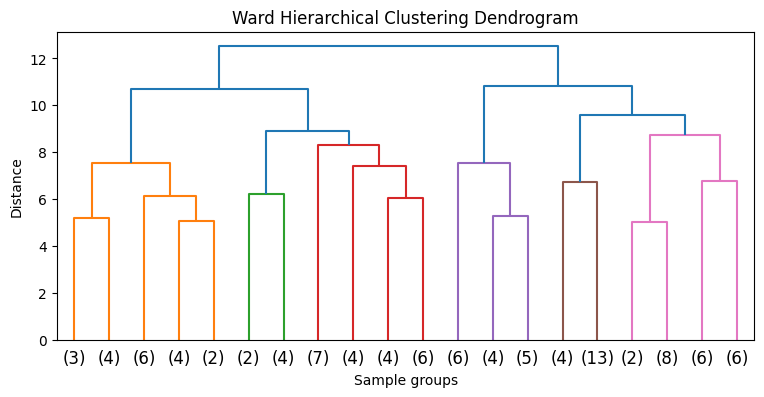

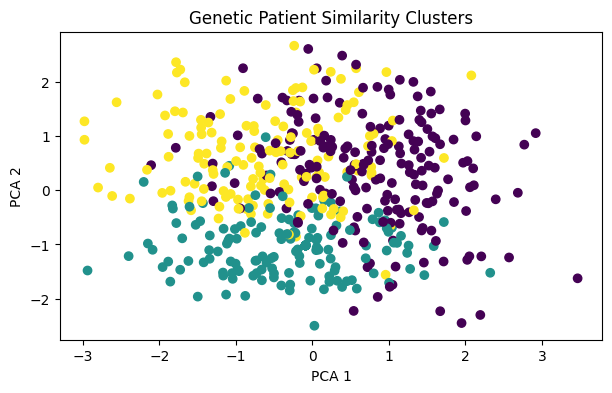

K-Means silhouette score: 0.1024
Results saved: genetic_cluster_results.csv


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

# Select numerical columns
drop_cols = [
    c for c in df.columns
    if any(w in c.lower() for w in
           ['id', 'name', 'target', 'label', 'class',
            'diagnosis', 'disorder', 'patient'])
]
data = df.drop(columns=drop_cols, errors='ignore')
data = data.select_dtypes(include=np.number)
data = data.loc[:, data.nunique(dropna=True) > 1]
data = data.replace([np.inf, -np.inf], np.nan).dropna(axis=1, how='all')

if data.shape[1] < 2:
    raise ValueError("Not enough numeric features. Check the dataset.")

X = SimpleImputer(strategy='median').fit_transform(data)
X = StandardScaler().fit_transform(X)

# Sample up to 500 rows for speed
rng = np.random.RandomState(42)
if len(X) > 500:
    idx = rng.choice(len(X), 500, replace=False)
    X = X[idx]

# Ward hierarchical clustering
labels = AgglomerativeClustering(
    n_clusters=3, linkage='ward'
).fit_predict(X)

print("Rows analyzed:", len(X))
print("Hierarchical clusters:", np.unique(labels))
print("Hierarchical silhouette score:",
      round(silhouette_score(X, labels), 4))
print("Cluster sizes:\n",
      __import__('pandas').Series(labels).value_counts().sort_index())

# Dendrogram
Z = linkage(X[:min(100, len(X))], method='ward')
plt.figure(figsize=(9, 4))
dendrogram(Z, truncate_mode='lastp', p=20)
plt.title("Ward Hierarchical Clustering Dendrogram")
plt.xlabel("Sample groups")
plt.ylabel("Distance")
plt.show()

# PCA visualization
points = PCA(n_components=2).fit_transform(X)
plt.figure(figsize=(7, 4))
plt.scatter(points[:, 0], points[:, 1], c=labels)
plt.title("Genetic Patient Similarity Clusters")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

# K-Means comparison
km_labels = KMeans(
    n_clusters=3, random_state=42, n_init=10
).fit_predict(X)
print("K-Means silhouette score:",
      round(silhouette_score(X, km_labels), 4))

# Save result file
import pandas as pd
results = pd.DataFrame({
    "Row": np.arange(1, len(X) + 1),
    "Hierarchical_Cluster": labels,
    "KMeans_Cluster": km_labels
})
results.to_csv("genetic_cluster_results.csv", index=False)
print("Results saved: genetic_cluster_results.csv")


In [6]:
from google.colab import files
files.download("genetic_cluster_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
!pip -q install flask


In [4]:
from flask import Flask, jsonify
import pandas as pd
import os

app = Flask(__name__)

file_path = "/content/genetic_cluster_results.csv"
df = pd.read_csv(file_path)

@app.route("/")
def home():
    return "Genetic Patient Similarity API is ready!"

@app.route("/results")
def results():
    return jsonify(df.head(10).to_dict(orient="records"))

print("API code ready!")


API code ready!


In [7]:
from threading import Thread

def run_api():
    app.run(
        host="0.0.0.0",
        port=5000,
        use_reloader=False
    )

api_thread = Thread(target=run_api, daemon=True)
api_thread.start()

print("Flask server started!")


Flask server started!


In [8]:



import requests

response = requests.get("http://127.0.0.1:5000/")

print("Status:", response.status_code)
print("Response:", response.text)


INFO:werkzeug:127.0.0.1 - - [03/Nov/2026 07:07:54] "GET / HTTP/1.1" 200 -


Status: 200
Response: Genetic Patient Similarity API is ready!


In [9]:
!pip -q install streamlit


In [10]:
%%writefile app.py
import streamlit as st
import pandas as pd

st.set_page_config(page_title="Genetic Patient Similarity", layout="wide")

st.title("Genetic Patient Similarity Analysis")
st.write("Patient Clustering Dashboard")

df = pd.read_csv("/content/genetic_cluster_results.csv")

st.subheader("Clustering Results")
st.dataframe(df, use_container_width=True)

cluster_col = next(
    (c for c in df.columns if "cluster" in c.lower()),
    None
)

if cluster_col:
    st.subheader("Patients in Each Cluster")
    st.bar_chart(df[cluster_col].value_counts())

st.success("Dashboard loaded successfully!")


Writing app.py


In [11]:
!streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &

In [12]:
!cat streamlit.log



2026-11-03 07:08:23.528 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.90.145.191:8501



In [14]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴your url is: https://hip-falcons-tickle.loca.lt
^C


In [15]:
!curl -I http://127.0.0.1:8501


^C


In [16]:
!fuser -k 8501/tcp 2>/dev/null

In [17]:
!streamlit run app.py --server.address 0.0.0.0 --server.port 8501 > streamlit.log 2>&1 &



In [18]:
!cat streamlit.log



2026-11-03 07:39:56.325 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.90.145.191:8501



In [19]:
!timeout 8s curl -v http://127.0.0.1:8501/_stcore/health


*   Trying 127.0.0.1:8501...
* Connected to 127.0.0.1 (127.0.0.1) port 8501
> GET /_stcore/health HTTP/1.1
> Host: 127.0.0.1:8501
> User-Agent: curl/8.5.0
> Accept: */*
> 
< HTTP/1.1 200 OK
< date: Tue, 03 Nov 2026 07:43:42 GMT
< server: uvicorn
< content-length: 2
< content-type: text/plain; charset=utf-8
< cache-control: no-cache
< set-cookie: _streamlit_xsrf=2|4a0f3ae9|e45abfb86888331199ff2c847ea97235|1793691822; Path=/; SameSite=Lax
< 
* Connection #0 to host 127.0.0.1 left intact
ok

In [20]:
import os
print(os.listdir("/content"))

['.config', 'genetic_cluster_results.csv', 'train_genetic_disorders.csv', 'app.py', 'streamlit.log', 'sample_data']


In [21]:
%%writefile README.md
# Genetic Patient Similarity

## Project Description
This project uses Machine Learning clustering
to identify similarities between genetic patients.

## Technologies Used
- Python
- Pandas
- Scikit-learn
- K-Means Clustering
- Hierarchical Clustering
- Flask API
- Streamlit Dashboard

## Features
- Patient similarity analysis
- K-Means clustering
- Hierarchical clustering
- Cluster visualization
- Flask API
- Streamlit dashboard


Writing README.md


In [22]:
from google.colab import files
files.download('/content/app.py')
files.download('/content/genetic_cluster_results.csv')
files.download('/content/README.md')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!curl -s https://api.ipify.org

In [ ]:
!cat streamlit.log

In [ ]:
!streamlit run app.py --server.port 8502 > streamlit.log 2>&1 &


In [ ]:
!cat streamlit.log

In [ ]:
!npx localtunnel --port 8502


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Genetic Patient Similarity",
    layout="wide"
)

st.title("Genetic Patient Similarity Analysis")
st.write("Patient Clustering Dashboard")

try:
    df = pd.read_csv("/content/genetic_cluster_results.csv")

    st.subheader("Clustering Results")
    # Avoid display errors caused by mixed data types
    st.dataframe(
        df.astype(str),
        use_container_width=True
    )

    cluster_col = next(
        (c for c in df.columns
         if "cluster" in c.lower()),
        None
    )

    if cluster_col:
        st.subheader("Patients in Each Cluster")
        counts = df[cluster_col].value_counts()
        st.dataframe(
            counts.rename_axis("Cluster").reset_index(
                name="Patient Count"
            ),
            use_container_width=True
        )
        st.bar_chart(counts)
    else:
        st.warning(
            "Cluster column not found. "
            "Please check the CSV column names."
        )

except Exception as e:
    st.error(f"Error: {e}")

st.success("Dashboard loaded successfully!")

In [ ]:
!npx localtunnel --port 8502

In [ ]:
!curl -I --max-time 10 http://127.0.0.1:8502

In [ ]:
!streamlit run app.py --server.port 8502 --server.address 0.0.0.0



2026-10-25 12:48:56.853 Uvicorn server started on 0.0.0.0:8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.10.40.63:8502



In [ ]:
!npx localtunnel --port 8502